# 01_LoadSilverData Notebook

This notebook is used to create the silver layer data set which can be used for feature engineering.

Some checks on the consistency of the manually created metadata table are done and the images are cropped and saved as silver data.

## 1. Import libaries and define parameters

In [1]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image, ExifTags

In [26]:
# path to pictures and meta data for mpictures
imageDir = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data\01_bronze'
silverDir = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data\02_silver'
silverDir2 = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data\02_silver2'
metaDataPath = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data'
metaDataFile  = r'\imageMetaData.xlsx'

## 2. Create dataframe with meta data

In [3]:
# read meta data to dataframe
df = pd.read_excel(metaDataPath + metaDataFile)

In [4]:
# extend df with image filename
fileList = [f'IMG_{name}.JPG' for name in df['imgNumber']]
df['imgFileName'] = fileList
df.head()

,concentration,probeQuantity,iso,imgNumber,imgFileName
0,0.5,20,800,1542,IMG_1542.JPG
1,0.5,20,800,1543,IMG_1543.JPG
2,0.5,20,800,1544,IMG_1544.JPG
3,0.5,20,800,1545,IMG_1545.JPG
4,0.5,40,800,1546,IMG_1546.JPG


### Check consistency of manually created meta data

In [5]:
# check that all images are included in the df
allImages = set(os.listdir(imageDir))
missing = [f for f in df['imgFileName'] if f not in allImages]

if missing:
    print("Missing images:", missing)
else:
    print('All images included in dataframe!')

All images included in dataframe!


### Explore image meta data 

In [6]:
# Extract human-readable EXIF tag names
TAGS = ExifTags.TAGS
# Store results here
metadata_list = []

for filename in df['imgFileName']:
    filepath = os.path.join(imageDir, filename)
    img = Image.open(filepath)
    exif_data = img._getexif()
    # Build a dictionary for this image
    meta = {'filename': filename}
    if exif_data:
        for tag_id, value in exif_data.items():
            tag = TAGS.get(tag_id, tag_id)
            if not isinstance(value, dict):  # Skip nested dicts
                meta[tag] = value
            else:
                # show which tags are contained in a dict
                print(tag)

    metadata_list.append(meta)
    
# Convert to DataFrame
df_meta = pd.DataFrame(metadata_list)

GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo
GPSInfo


In [7]:
df_meta.head()

,filename,ResolutionUnit,ExifOffset,Make,Model,YResolution,Orientation,DateTime,YCbCrPositioning,Copyright,...,SensitivityType,WhiteBalance,RecommendedExposureIndex,CameraOwnerName,BodySerialNumber,LensSpecification,LensModel,LensSerialNumber,SceneCaptureType,MakerNote
0,IMG_1542.JPG,2,360,Canon,Canon EOS 700D,72.0,1,2025:05:20 16:03:25,2,,...,2,1,800,,053076026964,"(18.0, 55.0, 0.0, 0.0)",EF-S18-55mm f/3.5-5.6 IS,0000145b88,0,b'(\x00\x01\x00\x03\x001\x00\x00\x00t\x05\x00\...
1,IMG_1543.JPG,2,360,Canon,Canon EOS 700D,72.0,1,2025:05:20 16:03:30,2,,...,2,1,800,,053076026964,"(18.0, 55.0, 0.0, 0.0)",EF-S18-55mm f/3.5-5.6 IS,0000145b88,0,b'(\x00\x01\x00\x03\x001\x00\x00\x00t\x05\x00\...
2,IMG_1544.JPG,2,360,Canon,Canon EOS 700D,72.0,1,2025:05:20 16:04:58,2,,...,2,1,800,,053076026964,"(18.0, 55.0, 0.0, 0.0)",EF-S18-55mm f/3.5-5.6 IS,0000145b88,0,b'(\x00\x01\x00\x03\x001\x00\x00\x00t\x05\x00\...
3,IMG_1545.JPG,2,360,Canon,Canon EOS 700D,72.0,1,2025:05:20 16:05:00,2,,...,2,1,800,,053076026964,"(18.0, 55.0, 0.0, 0.0)",EF-S18-55mm f/3.5-5.6 IS,0000145b88,0,b'(\x00\x01\x00\x03\x001\x00\x00\x00t\x05\x00\...
4,IMG_1546.JPG,2,360,Canon,Canon EOS 700D,72.0,1,2025:05:20 16:05:21,2,,...,2,1,800,,053076026964,"(18.0, 55.0, 0.0, 0.0)",EF-S18-55mm f/3.5-5.6 IS,0000145b88,0,b'(\x00\x01\x00\x03\x001\x00\x00\x00t\x05\x00\...


In [8]:
# Display columns that vary
print("\nColumns with more than one unique value:")
print(df_meta.nunique()[df_meta.nunique() > 1])


Columns with more than one unique value:
filename                    159
DateTime                    159
DateTimeOriginal            159
DateTimeDigitized           159
SubsecTime                   81
SubsecTimeOriginal           81
SubsecTimeDigitized          81
ISOSpeedRatings               4
RecommendedExposureIndex      4
MakerNote                   159
dtype: int64


df_meta[['ISOSpeedRatings','RecommendedExposureIndex']]

In [9]:
# check that iso value is correct in meta data table
(df_meta['ISOSpeedRatings'] == df['iso']).all()

True

## 3. Example of one image

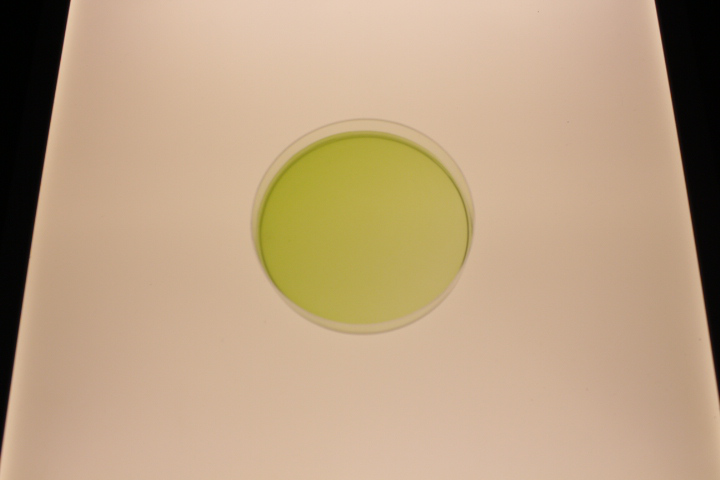

In [10]:
image = Image.open(imageDir + '\\' + df['imgFileName'][0]).convert("RGB")
image

In [11]:
# Convert to NumPy array
image_array = np.array(image)  # Shape: (height, width, 3)

In [12]:
# Extract R, G, B channels
R = image_array[:, :, 0]
G = image_array[:, :, 1]
B = image_array[:, :, 2]

In [13]:
# Compute light intensity (grayscale approximation)
# Common formula: 0.299*R + 0.587*G + 0.114*B
intensity = 0.299 * R + 0.587 * G + 0.114 * B

In [14]:
# Example: Print shape and sample pixel
print("Shape:", image_array.shape)
print("RGB at (0,0):", image_array[0, 0])
print("Intensity at (0,0):", intensity[0, 0])

Shape: (480, 720, 3)
RGB at (0,0): [1 1 1]
Intensity at (0,0): 0.9999999999999999


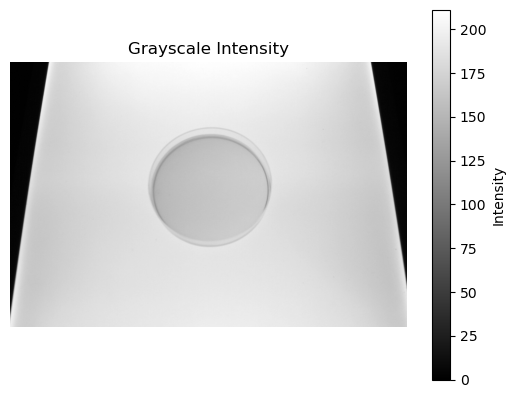

In [15]:
# Plot intensity map
plt.imshow(intensity, cmap='gray')
plt.title("Grayscale Intensity")
plt.axis('off')
plt.colorbar(label='Intensity')
plt.show()

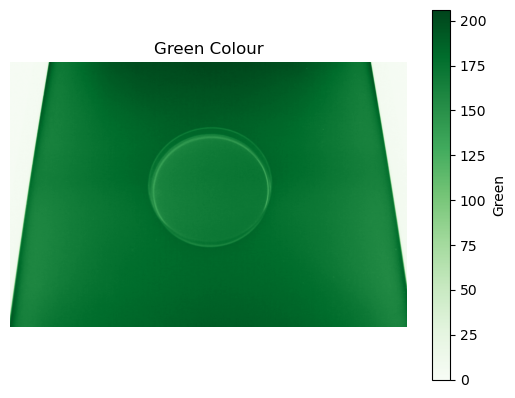

In [16]:
plt.imshow(G, cmap='Greens')
plt.title("Green Colour")
plt.axis('off')
plt.colorbar(label='Green')
plt.show()

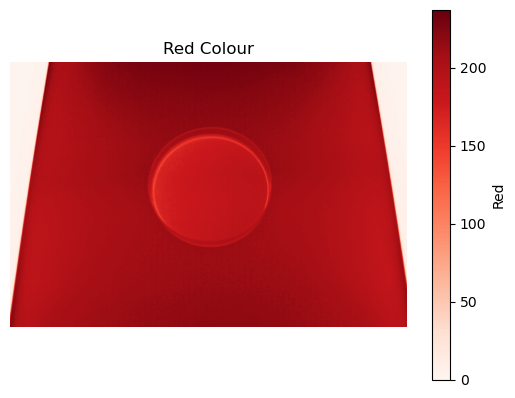

In [17]:
plt.imshow(R, cmap='Reds')
plt.title("Red Colour")
plt.axis('off')
plt.colorbar(label='Red')
plt.show()

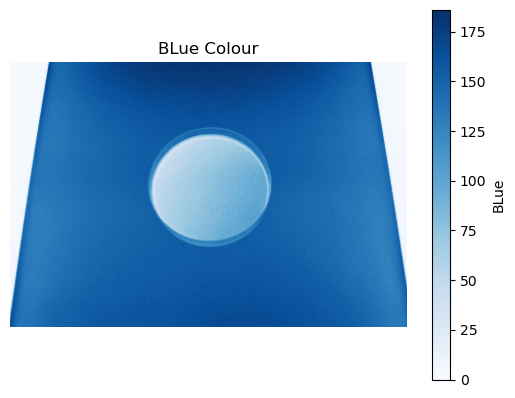

In [18]:
plt.imshow(B, cmap='Blues')
plt.title("BLue Colour")
plt.axis('off')
plt.colorbar(label='BLue')
plt.show()

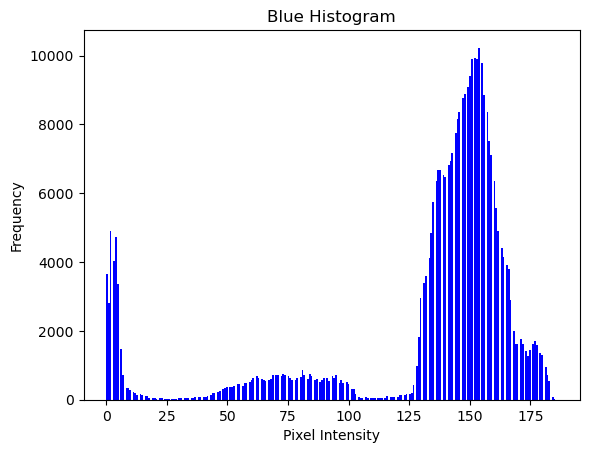

In [19]:
plt.hist(B.ravel(), bins=256, color='blue')
plt.title("Blue Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

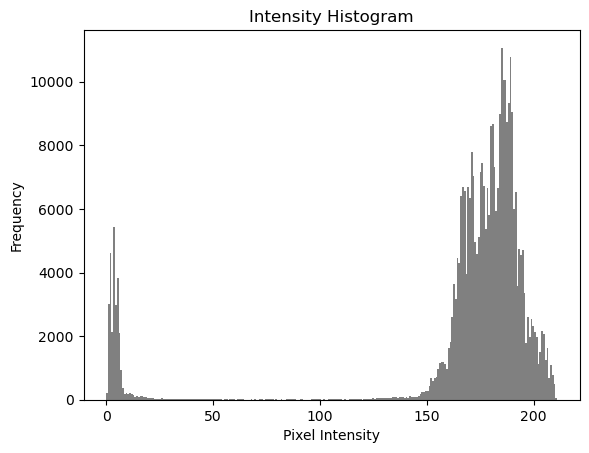

In [20]:
plt.hist(intensity.ravel(), bins=256, color='gray')
plt.title("Intensity Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

## 4. Crop images and save as silver data

### Crop image that whole 'Petrischale' is still visible

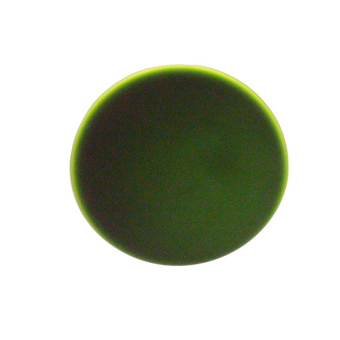

In [27]:
# Define crop box: (left, top, right, bottom)
crop_box = (190, 70, 720 - 190, 480 - 70)
img.crop(crop_box)

In [22]:
# crop all images and save in silver data folder
for filename in df['imgFileName']:
    filepath = os.path.join(imageDir, filename)
    img = Image.open(filepath)
    cropImg = img.crop(crop_box)
    cropImg.save(silverDir +'\\' +  filename, format="JPEG")

### Crop image that only fluid is visible

(120, 120)


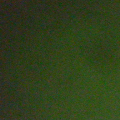

In [43]:
# Define crop box: (left, top, right, bottom)
crop_box = (310, 180, 720 - 290, 480 - 180)
print(img.crop(crop_box).size)
img.crop(crop_box)

In [44]:
# crop all images and save in silver data folder
for filename in df['imgFileName']:
    filepath = os.path.join(imageDir, filename)
    img = Image.open(filepath)
    cropImg = img.crop(crop_box)
    cropImg.save(silverDir2 +'\\' +  filename, format="JPEG")